## Импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("insurance.csv")
df["age"] = df["age"].fillna(df["age"].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(1070, 8)


In [3]:
median_price = y_train.median()
y_train_class = (y_train > median_price).astype(int)
y_test_class = (y_test > median_price).astype(int)

clf = LogisticRegression(max_iter=1000, random_state = 42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])
display(
    pd.DataFrame(
        {
            "Вероятность (Сигмоида)": sample_probs,
            "Класс (Порог 0.5)": sample_preds,
            "Факт": y_test_class.iloc[:5].values
        }
    ).round(3)
)
print(f"Точность классификации (Accuracy): {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.558,1,0
1,0.190,0,0
2,1.000,1,1
3,0.485,0,0
4,0.978,1,1


Точность классификации (Accuracy): 0.9104


## Регрессия: MHK и SGD

In [4]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time()-start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol = 1e-3, eta0 = 0.01, learning_rate="adaptive", random_state = 42
)
sgd.fit(X_train, y_train)
time_sgd = time.time()-start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"MHK (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:,.5f} сек")
print(f"SGD (Итеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:,.5f} сек")

MHK (Аналитический): RMSE = $5,796.28 | R2 = 0.78 | Время = 0.00100 сек
SGD (Итеративный): RMSE = $5,796.14 | R2 = 0.78 | Время = 0.09175 сек


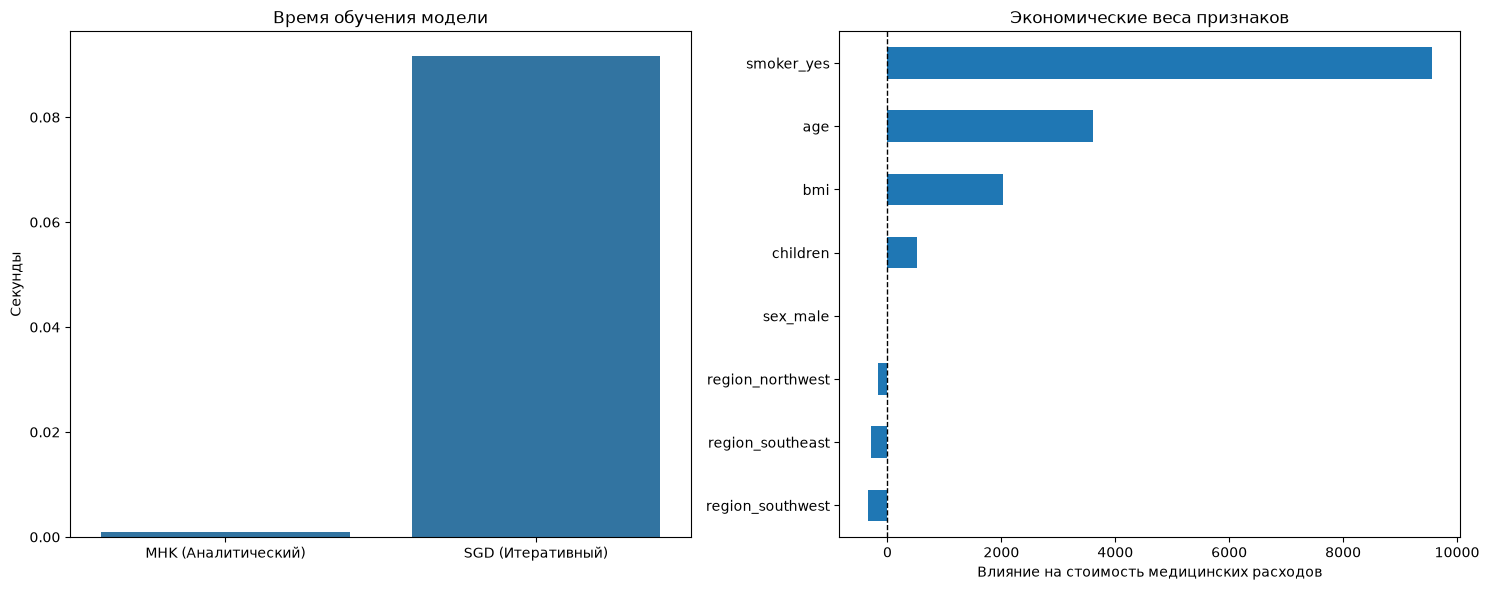

In [5]:
fig, axes = plt.subplots(1,2, figsize=(15,6))
# 1. Сравнение времени выполнения
sns.barplot(
    x = ["MHK (Аналитический)", "SGD (Итеративный)"],
    y = [time_ols, time_sgd],
    ax = axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax = axes[1])
axes[1].set_title("Экономические веса признаков")
axes[1].set_xlabel("Влияние на стоимость медицинских расходов")
axes[1].axvline(0, color = "black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()